# Proyecto Estadísticas de YouTube – Avances II
**Universidad de Cundinamarca · Especialización en Inteligencia Artificial · Procesamiento de Lenguaje Natural**  
Docente: Paul Alexander Díaz Montaña · Estudiante: Yohan Nicolás Gómez Castañeda

Objetivo: predecir el desempeño de un video de YouTube a partir de sus comentarios mediante una arquitectura de dos etapas (clasificador de sentimiento por comentario y modelo de desempeño por video).

**Datos:** descargar `videos-stats.csv` y `comments.csv` de https://www.kaggle.com/datasets/advaypatil/youtube-statistics en la carpeta `data/`.

## 0. Instalación (Google Colab)

In [1]:
# !pip install -q vaderSentiment textblob xgboost statsmodels

## Configuración e importaciones

In [2]:
import sys, json, re, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import StratifiedKFold, KFold, cross_validate, train_test_split, GroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             r2_score, mean_absolute_error, mean_squared_error, roc_auc_score)
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.decomposition import TruncatedSVD
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
from xgboost import XGBRegressor, XGBClassifier
warnings.filterwarnings("ignore")

VID, COM, OUT = "../data/videos-stats.csv", "../data/comments.csv", Path("../reports"); OUT.mkdir(parents=True, exist_ok=True)
R = {}  # resultados
SEED = 42
plt.rcParams.update({"figure.dpi": 150, "font.size": 9, "font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif"], "mathtext.fontset": "stix", "axes.spines.top": False, "axes.spines.right": False})
C1, C2, C3 = "#2a6f97", "#e07a5f", "#81b29a"

## 1. Carga y limpieza

In [3]:
v = pd.read_csv(VID).drop(columns=[c for c in ["Unnamed: 0"] if c in pd.read_csv(VID, nrows=1)])
c = pd.read_csv(COM).drop(columns=[c for c in ["Unnamed: 0"] if c in pd.read_csv(COM, nrows=1)])
R["raw"] = dict(videos=len(v), comments=len(c), v_null=v.isna().sum().to_dict(), c_null=c.isna().sum().to_dict(),
                v_dup=int(v.duplicated("Video ID").sum()), c_dup=int(c.duplicated(["Video ID", "Comment"]).sum()))
v = v.drop_duplicates("Video ID").dropna(subset=["Views"])
R["hidden_counts"] = dict(likes=int((v.Likes < 0).sum()), comments=int((v.Comments < 0).sum()))
for col in ["Likes", "Comments"]: v.loc[v[col] < 0, col] = np.nan  # -1 = contador oculto/deshabilitado
v = v[(v.Views > 0)]
v["Published At"] = pd.to_datetime(v["Published At"], errors="coerce")
ref = v["Published At"].max()
v["age_days"] = (ref - v["Published At"]).dt.days.clip(lower=1)
c = c.dropna(subset=["Comment", "Sentiment"]).drop_duplicates(["Video ID", "Comment"])
c["Sentiment"] = c["Sentiment"].astype(int); c = c[c.Sentiment.isin([0, 1, 2])]
c = c[c["Video ID"].isin(v["Video ID"])]
R["clean"] = dict(videos=len(v), comments=len(c), keywords=int(v.Keyword.nunique()),
                  comments_per_video=c.groupby("Video ID").size().describe().round(2).to_dict(),
                  date_min=str(v["Published At"].min().date()), date_max=str(ref.date()))

def clean_text(s):
    s = str(s).lower()
    s = re.sub(r"http\S+|www\.\S+", " ", s)
    s = re.sub(r"[@#]\w+", " ", s)
    s = re.sub(r"[^a-záéíóúñü0-9\s!?']", " ", s)  # conserva ! ? (intensidad)
    return re.sub(r"\s+", " ", s).strip()
c["text"] = c["Comment"].map(clean_text)
c["len_words"] = c["Comment"].astype(str).str.split().str.len()
c["has_q"] = c["Comment"].astype(str).str.contains(r"\?").astype(int)
c["has_excl"] = c["Comment"].astype(str).str.contains("!").astype(int)
c["emoji"] = c["Comment"].astype(str).map(lambda s: sum(ord(ch) > 0x2600 for ch in s))
c["non_ascii_ratio"] = c["Comment"].astype(str).map(lambda s: sum(ord(ch) > 127 for ch in s) / max(len(s), 1))

## 2. Estadística descriptiva e inferencial

In [4]:
v["engagement"] = (v.Likes + v.Comments) / v.Views
v["like_rate"] = v.Likes / v.Views
v["log_views"] = np.log10(v.Views)
desc = v[["Views", "Likes", "Comments", "engagement", "age_days"]].describe(percentiles=[.25, .5, .75, .95]).T
R["desc_videos"] = desc.round(4).to_dict(orient="index")
R["skew"] = {k: float(stats.skew(v[k], nan_policy="omit")) for k in ["Views", "Likes", "Comments"]}
R["skew_log"] = {k: float(stats.skew(np.log10(v[k] + 1), nan_policy="omit")) for k in ["Views", "Likes", "Comments"]}
# normalidad de log-views (D'Agostino)
R["normaltest_logviews"] = dict(zip(["stat", "p"], map(float, stats.normaltest(v.log_views))))
# correlaciones de Spearman entre métricas
num = v[["Views", "Likes", "Comments", "age_days", "engagement"]]
R["spearman"] = num.corr("spearman").round(3).to_dict()
# Kruskal–Wallis: ¿difieren las vistas por categoría (Keyword)?
groups = [g.log_views.values for _, g in v.groupby("Keyword") if len(g) >= 5]
H, p = stats.kruskal(*groups)
eps2 = (H - len(groups) + 1) / (len(v) - len(groups))
R["kruskal_views_keyword"] = dict(H=float(H), p=float(p), epsilon2=float(eps2), k=len(groups))
groups_e = [g.engagement.dropna().values for _, g in v.groupby("Keyword") if len(g) >= 5]
H2, p2 = stats.kruskal(*groups_e)
R["kruskal_eng_keyword"] = dict(H=float(H2), p=float(p2), epsilon2=float((H2 - len(groups_e) + 1) / (len(v) - len(groups_e))))
# Ley de potencia Likes ~ Views (regresión log-log, OLS) -> elasticidad
import statsmodels.api as sm
m = sm.OLS(np.log10(v.Likes + 1), sm.add_constant(v.log_views), missing="drop").fit()
R["loglog_likes_views"] = dict(beta=float(m.params.iloc[1]), ci=[float(x) for x in m.conf_int().iloc[1]], r2=float(m.rsquared))
m2 = sm.OLS(np.log10(v.Comments + 1), sm.add_constant(v.log_views), missing="drop").fit()
R["loglog_comments_views"] = dict(beta=float(m2.params.iloc[1]), ci=[float(x) for x in m2.conf_int().iloc[1]], r2=float(m2.rsquared))
# Sentimiento: distribución y chi-cuadrado sentimiento x categoría
R["sent_dist"] = c.Sentiment.value_counts().sort_index().to_dict()
ct = pd.crosstab(c.merge(v[["Video ID", "Keyword"]], on="Video ID").Keyword, c.merge(v[["Video ID", "Keyword"]], on="Video ID").Sentiment)
chi2, pc, dof, _ = stats.chi2_contingency(ct)
cramer = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
R["chi2_keyword_sentiment"] = dict(chi2=float(chi2), p=float(pc), dof=int(dof), cramers_v=float(cramer))
neg_share = (ct[0] / ct.sum(1)).sort_values(ascending=False) if 0 in ct else pd.Series(dtype=float)
R["top_neg_keywords"] = neg_share.head(5).round(3).to_dict(); R["low_neg_keywords"] = neg_share.tail(5).round(3).to_dict()
# Likes de comentario por sentimiento (Kruskal) – ¿la audiencia premia el tono?
gl = [g.Likes.dropna().values for _, g in c.groupby("Sentiment")]
Hl, pl = stats.kruskal(*gl)
R["kruskal_commentlikes_sent"] = dict(H=float(Hl), p=float(pl), medians=c.groupby("Sentiment").Likes.median().to_dict())
R["len_by_sent"] = c.groupby("Sentiment").len_words.median().to_dict()
# Concentración (Gini) de likes de comentarios dentro de cada video
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())) if x.sum() > 0 else np.nan
R["gini_comment_likes_median"] = float(c.groupby("Video ID").Likes.apply(gini).median())

## 3. Agregación comentario -> video (features NLP)

In [5]:
vader = SentimentIntensityAnalyzer()
c["vader"] = c.Comment.astype(str).map(lambda s: vader.polarity_scores(s)["compound"])
c["tb_pol"] = c.Comment.astype(str).map(lambda s: TextBlob(s).sentiment.polarity)
c["tb_subj"] = c.Comment.astype(str).map(lambda s: TextBlob(s).sentiment.subjectivity)
c["lw"] = np.log1p(c.Likes.fillna(0))
def agg(g):
    w = g.lw + 1
    return pd.Series(dict(
        n_com=len(g), pos_share=(g.Sentiment == 2).mean(), neg_share=(g.Sentiment == 0).mean(), neu_share=(g.Sentiment == 1).mean(),
        sent_mean=g.Sentiment.mean(), sent_wmean=np.average(g.Sentiment, weights=w),
        vader_mean=g.vader.mean(), vader_std=g.vader.std(), vader_wmean=np.average(g.vader, weights=w),
        tb_pol=g.tb_pol.mean(), tb_subj=g.tb_subj.mean(),
        clikes_log_mean=g.lw.mean(), clikes_log_max=g.lw.max(), clikes_gini=gini(g.Likes.fillna(0)),
        len_mean=g.len_words.mean(), q_share=g.has_q.mean(), excl_share=g.has_excl.mean(), emoji_mean=g.emoji.mean(),
        non_ascii=g.non_ascii_ratio.mean()))
fv = c.groupby("Video ID").apply(agg).reset_index()
d = v.merge(fv, on="Video ID", how="inner")
# Tópicos latentes del texto agregado (TF-IDF + SVD)
docs = c.groupby("Video ID").text.apply(" ".join).reindex(d["Video ID"]).fillna("")
tf_doc = TfidfVectorizer(min_df=3, max_df=.6, ngram_range=(1, 2), sublinear_tf=True, stop_words="english")
Xd = tf_doc.fit_transform(docs)
svd = TruncatedSVD(n_components=min(20, Xd.shape[1] - 1), random_state=SEED); T = svd.fit_transform(Xd)
for i in range(T.shape[1]): d[f"topic_{i}"] = T[:, i]
R["videos_modelables"] = len(d)
# Correlación parcial: ¿el sentimiento se relaciona con las vistas controlando por categoría y antigüedad?
d["log_likes"] = np.log10(d.Likes + 1); d["log_comments"] = np.log10(d.Comments + 1); d["log_age"] = np.log10(d.age_days)
pc_res = {}
Z = pd.get_dummies(d.Keyword, drop_first=True).astype(float); Z["log_age"] = d.log_age
for f in ["pos_share", "neg_share", "vader_mean", "clikes_log_mean", "clikes_log_max", "len_mean"]:
    rx = sm.OLS(d[f], sm.add_constant(Z)).fit().resid; ry = sm.OLS(d.log_views, sm.add_constant(Z)).fit().resid
    r, pp = stats.spearmanr(rx, ry); pc_res[f] = dict(rho=float(r), p=float(pp))
R["partial_corr_logviews"] = pc_res

## 4. Etapa A – Clasificador de sentimiento por comentario

In [6]:
y = c.Sentiment.values; X = c.text.values
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
tfw = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
modelsA = {
    "Dummy (clase mayoritaria)": make_pipeline(TfidfVectorizer(), DummyClassifier(strategy="most_frequent")),
    "Multinomial NB": make_pipeline(TfidfVectorizer(**tfw), MultinomialNB(alpha=.3)),
    "Complement NB": make_pipeline(TfidfVectorizer(**tfw), ComplementNB(alpha=.3)),
    "Regresión logística": make_pipeline(TfidfVectorizer(**tfw), LogisticRegression(C=4, max_iter=3000, class_weight="balanced")),
    "SVM lineal": make_pipeline(TfidfVectorizer(**tfw), LinearSVC(C=.5, class_weight="balanced")),
    "SVM lineal (word+char)": Pipeline([("f", __import__("sklearn.pipeline", fromlist=["FeatureUnion"]).FeatureUnion([
        ("w", TfidfVectorizer(**tfw)), ("ch", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True))])),
        ("m", LinearSVC(C=.3, class_weight="balanced"))]),
    "Random Forest": make_pipeline(TfidfVectorizer(max_features=20000, **tfw), RandomForestClassifier(200, n_jobs=-1, class_weight="balanced_subsample", random_state=SEED)),
}
from joblib import Memory
MEM = Memory("cache", verbose=0)
def _cv(name, X, y): return cross_validate(modelsA[name], X, y, cv=skf, scoring=["accuracy", "f1_macro", "f1_weighted"], n_jobs=1)
resA = {}
for name, mdl in modelsA.items():
    t0 = time.time()
    cv = MEM.cache(_cv)(name, X, y)
    resA[name] = {k: [float(cv[f"test_{k}"].mean()), float(cv[f"test_{k}"].std())] for k in ["accuracy", "f1_macro", "f1_weighted"]}
    resA[name]["sec"] = round(time.time() - t0, 1); print(name, resA[name])
# Léxicos (no entrenados): VADER y TextBlob con umbrales estándar
def lex_lab(s, lo, hi): return np.where(s >= hi, 2, np.where(s <= lo, 0, 1))
for name, pred in {"VADER (léxico)": lex_lab(c.vader.values, -.05, .05), "TextBlob (léxico)": lex_lab(c.tb_pol.values, -.05, .05)}.items():
    resA[name] = dict(accuracy=[float(accuracy_score(y, pred)), 0.0], f1_macro=[float(f1_score(y, pred, average="macro")), 0.0],
                      f1_weighted=[float(f1_score(y, pred, average="weighted")), 0.0], sec=0)
R["stageA"] = resA
bestA = max([k for k in resA if "Dummy" not in k], key=lambda k: resA[k]["f1_macro"][0]); R["bestA"] = bestA
# Hold-out para reporte detallado del mejor
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
mA = modelsA[bestA] if bestA in modelsA else modelsA["Regresión logística"]
mA.fit(Xtr, ytr); pA = mA.predict(Xte)
R["bestA_report"] = classification_report(yte, pA, output_dict=True, target_names=["Negativo", "Neutral", "Positivo"])
cmA = confusion_matrix(yte, pA, normalize="true")
# McNemar entre mejor modelo y VADER en hold-out
vte = lex_lab(c.vader.values, -.05, .05)[train_test_split(np.arange(len(y)), test_size=.2, stratify=y, random_state=SEED)[1]]
b = int(((pA == yte) & (vte != yte)).sum()); cc = int(((pA != yte) & (vte == yte)).sum())
R["mcnemar_bestA_vs_vader"] = dict(b=b, c=cc, chi2=float((abs(b - cc) - 1) ** 2 / (b + cc)), p=float(stats.chi2.sf((abs(b - cc) - 1) ** 2 / (b + cc), 1)))
# Palabras más discriminativas (regresión logística)
lr = make_pipeline(TfidfVectorizer(**tfw), LogisticRegression(C=4, max_iter=3000, class_weight="balanced")).fit(X, y)
voc = np.array(lr[0].get_feature_names_out()); coef = lr[1].coef_
R["top_terms"] = {lab: list(voc[np.argsort(coef[i])[-12:][::-1]]) for i, lab in enumerate(["Negativo", "Neutral", "Positivo"])}

Dummy (clase mayoritaria) {'accuracy': [0.6186118353437058, 0.00011423008854280366], 'f1_macro': [0.2547910980901507, 2.906589871979832e-05], 'f1_weighted': [0.47285037641695943, 0.0001412624810189092], 'sec': 2.0}


Multinomial NB {'accuracy': [0.6814047011738799, 0.0019684539736253004], 'f1_macro': [0.4600277131360868, 0.005411311568260775], 'f1_weighted': [0.6170787832073253, 0.003215947872905243], 'sec': 4.8}


Complement NB {'accuracy': [0.7371958261100062, 0.0050564835618557725], 'f1_macro': [0.6238879280327823, 0.007997409069551728], 'f1_weighted': [0.7219841727422003, 0.005692095542899019], 'sec': 5.1}


Regresión logística {'accuracy': [0.7618387786809027, 0.005126046707509372], 'f1_macro': [0.68475401802665, 0.007949058076769495], 'f1_weighted': [0.7654617917459661, 0.0048668035613589075], 'sec': 20.8}


SVM lineal {'accuracy': [0.7711005660413492, 0.004804012023996328], 'f1_macro': [0.6866293156412874, 0.009138572074453882], 'f1_weighted': [0.7696508798692381, 0.004871068825076968], 'sec': 6.0}


SVM lineal (word+char) {'accuracy': [0.7841659348345695, 0.008073295946886617], 'f1_macro': [0.7097244077198533, 0.011930580511607808], 'f1_weighted': [0.7845252914416532, 0.007981824968430537], 'sec': 31.3}


Random Forest {'accuracy': [0.6999281391037269, 0.002546600986150553], 'f1_macro': [0.4781332515682012, 0.006062657093657112], 'f1_weighted': [0.6450999210866634, 0.0038759009439721546], 'sec': 154.8}


## 5. Etapa B – Desempeño del video a partir de comentarios

In [7]:
# Etiquetas generadas por el modelo de etapa A (out-of-fold) para no usar la etiqueta "verdadera" -> realista en producción
from sklearn.model_selection import cross_val_predict
def _oof(name, X, y): return cross_val_predict(modelsA[name], X, y, cv=skf)
c["sent_pred"] = MEM.cache(lambda X, y: cross_val_predict(mA, X, y, cv=skf), ignore=[])(X, y) if False else MEM.cache(_oof)(bestA, X, y)
fv2 = c.groupby("Video ID").agg(pred_pos_share=("sent_pred", lambda s: (s == 2).mean()), pred_neg_share=("sent_pred", lambda s: (s == 0).mean())).reset_index()
d = d.merge(fv2, on="Video ID", how="left")
NLP = ["pred_pos_share", "pred_neg_share", "vader_mean", "vader_std", "vader_wmean", "tb_pol", "tb_subj",
       "clikes_log_mean", "clikes_log_max", "clikes_gini", "len_mean", "q_share", "excl_share", "emoji_mean", "non_ascii"] + [f"topic_{i}" for i in range(T.shape[1])]
META = ["log_age"]
CAT = ["Keyword"]
ENG = ["log_likes", "log_comments"]
feature_sets = {"Solo metadatos (categoría + antigüedad)": (META, CAT), "Solo NLP de comentarios": (NLP, []),
                "NLP + metadatos (propuesto)": (NLP + META, CAT), "NLP + metadatos + likes/comentarios (referencia, fuga)": (NLP + META + ENG, CAT)}
yreg = d.log_views.values
# Clasificación: video "exitoso" = vistas por encima de la mediana de su categoría (controla el efecto categoría)
d["high"] = (d.Views > d.groupby("Keyword").Views.transform("median")).astype(int); ycl = d.high.values
def prep(num, cat):
    t = [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num)]
    if cat: t.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return ColumnTransformer(t)
regs = {"Baseline (media)": DummyRegressor(), "Ridge": Ridge(alpha=3), "Random Forest": RandomForestRegressor(500, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, max_leaf_nodes=15, l2_regularization=1, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=500, learning_rate=.03, max_depth=4, subsample=.8, colsample_bytree=.7, reg_lambda=2, random_state=SEED, n_jobs=4)}
clfs = {"Baseline (estratificado)": DummyClassifier(strategy="stratified", random_state=SEED), "Regresión logística": LogisticRegression(C=.5, max_iter=3000),
        "Random Forest": RandomForestClassifier(500, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
        "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=.05, max_leaf_nodes=15, l2_regularization=1, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=400, learning_rate=.03, max_depth=4, subsample=.8, colsample_bytree=.7, random_state=SEED, n_jobs=4, eval_metric="logloss")}
kf = KFold(5, shuffle=True, random_state=SEED); skf5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
resB_reg, resB_cls = {}, {}
for fs, (num, cat) in feature_sets.items():
    Xb = d[num + cat]
    for name, mdl in regs.items():
        if name == "Baseline (media)" and fs != "Solo metadatos (categoría + antigüedad)": continue
        p = make_pipeline(prep(num, cat), mdl)
        cv = cross_validate(p, Xb, yreg, cv=kf, scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"])
        resB_reg[f"{name} | {fs}"] = dict(model=name, fs=fs, r2=[float(cv["test_r2"].mean()), float(cv["test_r2"].std())],
            mae=[float(-cv["test_neg_mean_absolute_error"].mean()), float(cv["test_neg_mean_absolute_error"].std())],
            rmse=[float(-cv["test_neg_root_mean_squared_error"].mean()), float(cv["test_neg_root_mean_squared_error"].std())])
    for name, mdl in clfs.items():
        if name.startswith("Baseline") and fs != "Solo metadatos (categoría + antigüedad)": continue
        p = make_pipeline(prep(num, cat), mdl)
        cv = cross_validate(p, Xb, ycl, cv=skf5, scoring=["roc_auc", "f1", "accuracy"])
        resB_cls[f"{name} | {fs}"] = dict(model=name, fs=fs, auc=[float(cv["test_roc_auc"].mean()), float(cv["test_roc_auc"].std())],
            f1=[float(cv["test_f1"].mean()), float(cv["test_f1"].std())], acc=[float(cv["test_accuracy"].mean()), float(cv["test_accuracy"].std())])
    print(fs, "done")
R["stageB_reg"] = resB_reg; R["stageB_cls"] = resB_cls
prop = "NLP + metadatos (propuesto)"
bestB = max([k for k in resB_reg if resB_reg[k]["fs"] == prop], key=lambda k: resB_reg[k]["r2"][0]); R["bestB_reg"] = bestB
bestBc = max([k for k in resB_cls if resB_cls[k]["fs"] == prop], key=lambda k: resB_cls[k]["auc"][0]); R["bestB_cls"] = bestBc
# Importancia por permutación del mejor regresor (hold-out 20%)
num, cat = feature_sets[prop]
dtr, dte = train_test_split(d, test_size=.2, random_state=SEED)
best_reg = make_pipeline(prep(num, cat), regs[resB_reg[bestB]["model"]]).fit(dtr[num + cat], dtr.log_views)
pr = best_reg.predict(dte[num + cat])
R["bestB_holdout"] = dict(r2=float(r2_score(dte.log_views, pr)), mae=float(mean_absolute_error(dte.log_views, pr)),
                          factor=float(10 ** mean_absolute_error(dte.log_views, pr)), spearman=float(stats.spearmanr(dte.log_views, pr)[0]))
pi = permutation_importance(best_reg, dte[num + cat], dte.log_views, n_repeats=20, random_state=SEED, scoring="r2")
imp = pd.Series(pi.importances_mean, index=num + cat).sort_values(ascending=False)
R["perm_importance"] = imp.head(15).round(4).to_dict()

# Selección de variables: filtro de información mutua + ablación por grupos
from sklearn.feature_selection import mutual_info_regression
mi = pd.Series(mutual_info_regression(d[NLP + META].fillna(0), yreg, random_state=SEED), index=NLP + META).sort_values(ascending=False)
R["mutual_info"] = mi.head(15).round(4).to_dict()
groups_ab = {"Sentimiento (modelo A + VADER + TextBlob)": ["pred_pos_share", "pred_neg_share", "vader_mean", "vader_std", "vader_wmean", "tb_pol", "tb_subj"],
             "Interacción con comentarios (likes de comentarios, Gini)": ["clikes_log_mean", "clikes_log_max", "clikes_gini"],
             "Estilo del texto (longitud, ?, !, emojis, idioma)": ["len_mean", "q_share", "excl_share", "emoji_mean", "non_ascii"],
             "Tópicos TF-IDF/SVD": [f"topic_{i}" for i in range(T.shape[1])], "Categoría (Keyword)": ["Keyword"], "Antigüedad": ["log_age"]}
base_r2 = resB_reg[bestB]["r2"][0]; abl = {}
mname = resB_reg[bestB]["model"]
for gname, cols in groups_ab.items():
    n2 = [x for x in num if x not in cols]; c2 = [x for x in cat if x not in cols]
    p = make_pipeline(prep(n2, c2), regs[mname])
    r2 = cross_validate(p, d[n2 + c2], yreg, cv=kf, scoring="r2")["test_score"].mean()
    abl[gname] = dict(r2_sin=float(r2), delta=float(base_r2 - r2))
R["ablation"] = abl

Solo metadatos (categoría + antigüedad) done


Solo NLP de comentarios done


NLP + metadatos (propuesto) done


NLP + metadatos + likes/comentarios (referencia, fuga) done


## 5b. Ajuste de hiperparámetros (GridSearchCV) y validación en hold-out

In [8]:
from sklearn.model_selection import GridSearchCV
TUNE = {}
# Etapa A: SVM lineal (palabras + caracteres); búsqueda en el 80 % de entrenamiento, evaluación en el 20 % reservado
gridA = {"m__C": [0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0], "f__ch__ngram_range": [(2, 5), (1, 4)]}
def _gsA(Xtr, ytr, grid):
    g = GridSearchCV(modelsA["SVM lineal (word+char)"], grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1_macro", n_jobs=2).fit(Xtr, ytr)
    return g.best_params_, float(g.best_score_), g.best_estimator_, len(g.cv_results_["params"])
bpA, bsA, beA, nA = MEM.cache(_gsA)(Xtr, ytr, gridA)
pA_t = beA.predict(Xte)
TUNE["A"] = dict(model="SVM lineal (word+char)", grid={k: [str(x) for x in v] for k, v in gridA.items()}, combos=nA, best_params={k: str(v) for k, v in bpA.items()},
                 cv_f1_macro=bsA, holdout_default=float(f1_score(yte, pA, average="macro")), holdout_tuned=float(f1_score(yte, pA_t, average="macro")),
                 holdout_acc_tuned=float(accuracy_score(yte, pA_t)))
# Etapa B: XGBoost (regresión) y regresión logística (clasificación)
SEL = [x for x in NLP if x not in ["len_mean", "q_share", "excl_share", "emoji_mean", "non_ascii"]]  # conjunto final sin variables de estilo
gridB = {"m__max_depth": [4, 6, 8], "m__learning_rate": [0.03, 0.06, 0.1], "m__n_estimators": [400, 800, 1200], "m__min_child_weight": [1, 5]}
xgb_base = Pipeline([("p", prep(num, cat)), ("m", XGBRegressor(subsample=.8, colsample_bytree=.7, reg_lambda=2, random_state=SEED, n_jobs=1))])
gB = GridSearchCV(xgb_base, gridB, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2", n_jobs=2).fit(dtr[num + cat], dtr.log_views)
prt = gB.predict(dte[num + cat])
TUNE["B_reg"] = dict(model="XGBoost", combos=len(gB.cv_results_["params"]), best_params={k: str(v) for k, v in gB.best_params_.items()}, cv_r2=float(gB.best_score_),
                     holdout_default=R["bestB_holdout"]["r2"], holdout_tuned=float(r2_score(dte.log_views, prt)), holdout_mae_tuned=float(mean_absolute_error(dte.log_views, prt)),
                     top5=[dict(params={k: str(v) for k, v in pp.items()}, r2=float(sc)) for pp, sc in sorted(zip(gB.cv_results_["params"], gB.cv_results_["mean_test_score"]), key=lambda t: -t[1])[:5]])
gridC = {"m__C": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}
lr_base = Pipeline([("p", prep(num, cat)), ("m", LogisticRegression(max_iter=3000))])
gC = GridSearchCV(lr_base, gridC, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc", n_jobs=2).fit(dtr[num + cat], dtr.high)
lr_def = Pipeline([("p", prep(num, cat)), ("m", LogisticRegression(C=.5, max_iter=3000))]).fit(dtr[num + cat], dtr.high)
TUNE["B_cls"] = dict(model="Regresión logística", combos=len(gC.cv_results_["params"]), best_params={k: str(v) for k, v in gC.best_params_.items()}, cv_auc=float(gC.best_score_),
                     holdout_default=float(roc_auc_score(dte.high, lr_def.predict_proba(dte[num + cat])[:, 1])),
                     holdout_tuned=float(roc_auc_score(dte.high, gC.predict_proba(dte[num + cat])[:, 1])))
# Conjunto final de variables (sin estilo) con los hiperparámetros ajustados, CV completa
bpB = {k.replace("m__", ""): v for k, v in gB.best_params_.items()}
xgb_t = lambda: XGBRegressor(subsample=.8, colsample_bytree=.7, reg_lambda=2, random_state=SEED, n_jobs=2, **bpB)
TUNE["final_cv"] = {}
for lab, cols in {"Propuesto (37 variables)": num, "Final sin estilo (32 variables)": SEL + META}.items():
    cvr = cross_validate(make_pipeline(prep(cols, cat), xgb_t()), d[cols + cat], yreg, cv=kf, scoring=["r2", "neg_mean_absolute_error"])
    TUNE["final_cv"][lab] = dict(n=len(cols) + 1, r2=[float(cvr["test_r2"].mean()), float(cvr["test_r2"].std())], mae=float(-cvr["test_neg_mean_absolute_error"].mean()))
# Objetivo alternativo: log10(likes) con las mismas variables (pregunta de la semana 7: ¿vistas o likes?)
dl = d.dropna(subset=["log_likes"])
cvl = cross_validate(make_pipeline(prep(SEL + META, cat), xgb_t()), dl[SEL + META + cat], dl.log_likes, cv=kf, scoring=["r2", "neg_mean_absolute_error"])
TUNE["likes_target"] = dict(r2=[float(cvl["test_r2"].mean()), float(cvl["test_r2"].std())], mae=float(-cvl["test_neg_mean_absolute_error"].mean()))
d.to_pickle(OUT / "features_video.pkl"); R["_final_num"] = SEL + META
R["tuning"] = TUNE; print("TUNING", json.dumps(TUNE, ensure_ascii=False))

TUNING {"A": {"model": "SVM lineal (word+char)", "grid": {"m__C": ["0.03", "0.05", "0.1", "0.2", "0.3", "0.5", "1.0"], "f__ch__ngram_range": ["(2, 5)", "(1, 4)"]}, "combos": 14, "best_params": {"f__ch__ngram_range": "(2, 5)", "m__C": "0.1"}, "cv_f1_macro": 0.6980698263941904, "holdout_default": 0.6995467461576035, "holdout_tuned": 0.6998803771946808, "holdout_acc_tuned": 0.7756339581036383}, "B_reg": {"model": "XGBoost", "combos": 54, "best_params": {"m__learning_rate": "0.06", "m__max_depth": "6", "m__min_child_weight": "1", "m__n_estimators": "1200"}, "cv_r2": 0.7673332615861994, "holdout_default": 0.8008833604439085, "holdout_tuned": 0.8000103162649548, "holdout_mae_tuned": 0.3409421151648153, "top5": [{"params": {"m__learning_rate": "0.06", "m__max_depth": "6", "m__min_child_weight": "1", "m__n_estimators": "1200"}, "r2": 0.7673332615861994}, {"params": {"m__learning_rate": "0.06", "m__max_depth": "6", "m__min_child_weight": "1", "m__n_estimators": "800"}, "r2": 0.767330809752531},

## 6. Figuras

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(10, 2.8))
ax[0].hist(v.Views, bins=50, color=C1); ax[0].set_title("Vistas (escala original)"); ax[0].set_yscale("log")
ax[1].hist(v.log_views, bins=40, color=C1); ax[1].set_title("log10(Vistas)")
ax[2].scatter(v.log_views, np.log10(v.Likes + 1).where(lambda x: x.notna()), s=4, alpha=.4, color=C1)
xx = np.linspace(v.log_views.min(), v.log_views.max(), 10); ax[2].plot(xx, m.params.iloc[0] + m.params.iloc[1] * xx, color=C2)
ax[2].set_xlabel("log10(Vistas)"); ax[2].set_ylabel("log10(Likes)"); ax[2].set_title(f"Ley de potencia, β={m.params.iloc[1]:.2f}")
plt.tight_layout(); plt.savefig(OUT / "f1_distribuciones.png"); plt.close()

order = v.groupby("Keyword").log_views.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.boxplot([v[v.Keyword == k].log_views for k in order], tick_labels=order, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#cfe0ea", color=C1), medianprops=dict(color=C2))
ax.set_ylabel("log10(Vistas)"); plt.xticks(rotation=70, fontsize=7); ax.set_title("Vistas por categoría (Keyword)")
plt.tight_layout(); plt.savefig(OUT / "f2_keyword.png"); plt.close()

ctn = ct.div(ct.sum(1), axis=0).sort_values(0, ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(ctn.index, ctn[0], color=C2, label="Negativo"); ax.bar(ctn.index, ctn[1], bottom=ctn[0], color="#bbbbbb", label="Neutral")
ax.bar(ctn.index, ctn[2], bottom=ctn[0] + ctn[1], color=C3, label="Positivo"); ax.legend(ncol=3, fontsize=7, loc="upper right", frameon=False)
plt.xticks(rotation=70, fontsize=7); ax.set_ylabel("Proporción"); ax.set_title("Sentimiento de los comentarios por categoría")
plt.tight_layout(); plt.savefig(OUT / "f3_sent_keyword.png"); plt.close()

names = sorted(resA, key=lambda k: resA[k]["f1_macro"][0])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax[0].barh(names, [resA[k]["f1_macro"][0] for k in names], xerr=[resA[k]["f1_macro"][1] for k in names], color=[C2 if k == bestA else C1 for k in names])
ax[0].set_xlabel("F1-macro (CV 5 folds)"); ax[0].set_title("Etapa A: clasificación de sentimiento")
im = ax[1].imshow(cmA, cmap="Blues", vmin=0, vmax=1); labs = ["Neg", "Neu", "Pos"]
ax[1].set_xticks(range(3), labs); ax[1].set_yticks(range(3), labs); ax[1].set_xlabel("Predicho"); ax[1].set_ylabel("Real")
for i in range(3):
    for j in range(3): ax[1].text(j, i, f"{cmA[i, j]:.2f}", ha="center", va="center", color="white" if cmA[i, j] > .5 else "black")
ax[1].set_title(f"Matriz de confusión – {bestA}", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "f4_stageA.png"); plt.close()

dfr = pd.DataFrame(resB_reg).T; dfr["r2m"] = dfr.r2.map(lambda x: x[0]); dfr["r2s"] = dfr.r2.map(lambda x: x[1])
fsl = list(feature_sets); models_l = [m_ for m_ in regs if m_ != "Baseline (media)"]
fig, ax = plt.subplots(figsize=(10, 3.6)); w = .2
for i, fs in enumerate(fsl):
    vals = [dfr.loc[f"{m_} | {fs}", "r2m"] for m_ in models_l]; errs = [dfr.loc[f"{m_} | {fs}", "r2s"] for m_ in models_l]
    ax.bar(np.arange(len(models_l)) + (i - 1.5) * w, vals, w, yerr=errs, label=fs, color=[C1, "#9ac1d9", C2, "#cccccc"][i])
ax.set_xticks(range(len(models_l)), models_l); ax.set_ylabel("R² (CV 5 folds)"); ax.axhline(0, color="k", lw=.5)
ax.set_ylim(0, 1); ax.legend(fontsize=7, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12)); ax.set_title("Etapa B: predicción de log10(Vistas) por conjunto de variables")
plt.tight_layout(); plt.savefig(OUT / "f5_stageB.png"); plt.close()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ii = imp.head(12)[::-1]; ax[0].barh(ii.index, ii.values, color=C1); ax[0].set_title("Importancia por permutación (ΔR²)"); ax[0].tick_params(labelsize=7)
ax[1].scatter(dte.log_views, pr, s=6, alpha=.5, color=C1); lim = [min(dte.log_views.min(), pr.min()), max(dte.log_views.max(), pr.max())]
ax[1].plot(lim, lim, color=C2, lw=1); ax[1].set_xlabel("log10(Vistas) real"); ax[1].set_ylabel("Predicho"); ax[1].set_title(f"Hold-out 20 % – R²={R['bestB_holdout']['r2']:.2f}")
plt.tight_layout(); plt.savefig(OUT / "f6_importance.png"); plt.close()

json.dump(R, open(OUT / "resultados.json", "w"), ensure_ascii=False, indent=1, default=str)
print("OK", bestA, bestB, bestBc)

OK SVM lineal (word+char) XGBoost | NLP + metadatos (propuesto) Regresión logística | NLP + metadatos (propuesto)


## 7. Curvas de aprendizaje: ¿son suficientes los datos?

In [10]:
import sys, json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline, FeatureUnion, make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
SEED = 42
plt.rcParams.update({"figure.dpi": 150, "font.size": 9, "font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif"],
                     "axes.spines.top": False, "axes.spines.right": False})
R = json.load(open(OUT / "resultados.json"))
c = pd.read_csv(COM).dropna(subset=["Comment"]).drop_duplicates(["Video ID", "Comment"])
v = pd.read_csv(VID).drop_duplicates("Video ID")
c = c[c["Video ID"].isin(v["Video ID"])]; c = c[c.Sentiment.isin([0, 1, 2])]
def clean_text(s):
    s = str(s).lower(); s = re.sub(r"http\S+|www\.\S+", " ", s); s = re.sub(r"[@#]\w+", " ", s)
    s = re.sub(r"[^a-záéíóúñü0-9\s!?']", " ", s); return re.sub(r"\s+", " ", s).strip()
X = c.Comment.map(clean_text).values; y = c.Sentiment.astype(int).values
bp = R["tuning"]["A"]["best_params"]
svm = Pipeline([("f", FeatureUnion([("w", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("ch", TfidfVectorizer(analyzer="char_wb", ngram_range=eval(bp["f__ch__ngram_range"]), min_df=3, sublinear_tf=True))])),
        ("m", LinearSVC(C=float(bp["m__C"]), class_weight="balanced"))])
sizes = np.array([.1, .25, .5, .75, 1.0])
nA, trA, teA = learning_curve(svm, X, y, train_sizes=sizes, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1_macro", n_jobs=2, shuffle=True, random_state=SEED)
d = pd.read_pickle(OUT / "features_video.pkl")
num, cat = R["_final_num"], ["Keyword"]
bpB = {k.replace("m__", ""): eval(v) if v.replace(".", "").isdigit() else v for k, v in R["tuning"]["B_reg"]["best_params"].items()}
pre = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
xgb = make_pipeline(pre, XGBRegressor(subsample=.8, colsample_bytree=.7, reg_lambda=2, random_state=SEED, n_jobs=1, **bpB))
nB, trB, teB = learning_curve(xgb, d[num + cat], d.log_views, train_sizes=sizes, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2", n_jobs=2, shuffle=True, random_state=SEED)
LC = dict(A=dict(n=nA.tolist(), train=trA.mean(1).tolist(), test=teA.mean(1).tolist(), test_sd=teA.std(1).tolist()),
          B=dict(n=nB.tolist(), train=trB.mean(1).tolist(), test=teB.mean(1).tolist(), test_sd=teB.std(1).tolist()))
json.dump(LC, open(OUT / "curvas.json", "w"), indent=1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, n, tr, te, lab, t in [(ax[0], nA, trA, teA, "F1-macro", "Etapa A: comentarios de entrenamiento"), (ax[1], nB, trB, teB, "R²", "Etapa B: videos de entrenamiento")]:
    a.plot(n, tr.mean(1), "o--", color="#81b29a", label="Entrenamiento")
    a.plot(n, te.mean(1), "o-", color="#2a6f97", label="Validación")
    a.fill_between(n, te.mean(1) - te.std(1), te.mean(1) + te.std(1), color="#2a6f97", alpha=.15)
    a.set_xlabel(t); a.set_ylabel(lab); a.legend(frameon=False, fontsize=8)
ax[0].set_title("Curva de aprendizaje – clasificador de sentimiento"); ax[1].set_title("Curva de aprendizaje – predicción de log10(vistas)")
plt.tight_layout(); plt.savefig(OUT / "f7_curvas.png"); plt.close()
print(json.dumps(LC))

{"A": {"n": [1452, 3631, 7263, 10895, 14527], "train": [0.9708267071234082, 0.9531024455270212, 0.9365422336087313, 0.928686551706656, 0.9239391102344772], "test": [0.5912687947995234, 0.6396220679352349, 0.6796050570290137, 0.694354947324592, 0.705878614174112], "test_sd": [0.012089885288706652, 0.01045160590395072, 0.010869111558030779, 0.008554844667211145, 0.0071258208553671275]}, "B": {"n": [149, 373, 746, 1119, 1493], "train": [0.9999998443710842, 0.9999998294154245, 0.9999998025931403, 0.9999997687976443, 0.9999995410610065], "test": [0.6523187057711066, 0.7196421000067991, 0.7557734564012736, 0.7795517154752435, 0.787905895221618], "test_sd": [0.02555215992767049, 0.021515486415173368, 0.014289567951694792, 0.01879258177327557, 0.01477815123464852]}}


## Figuras generadas

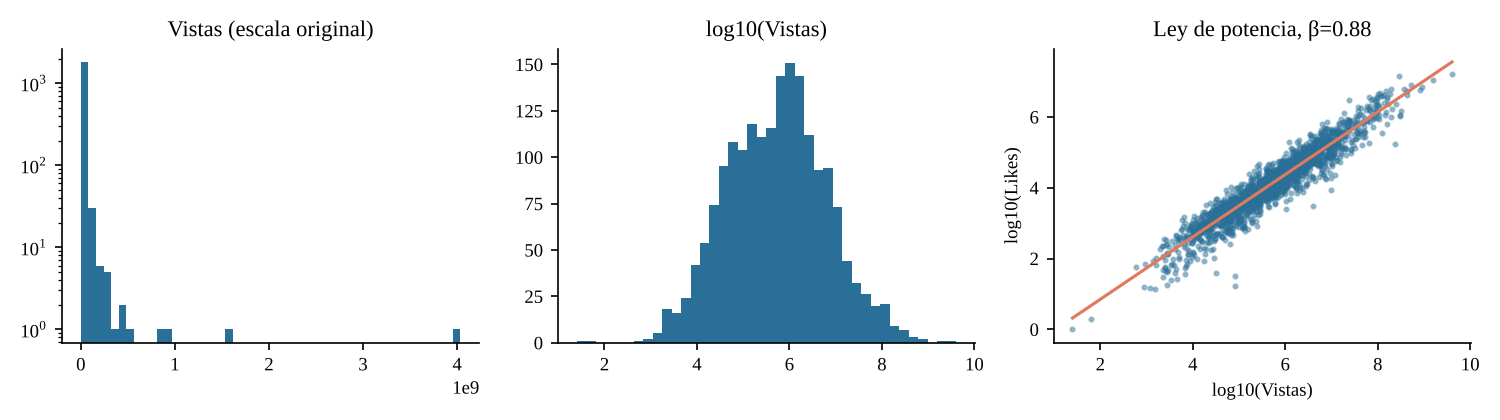

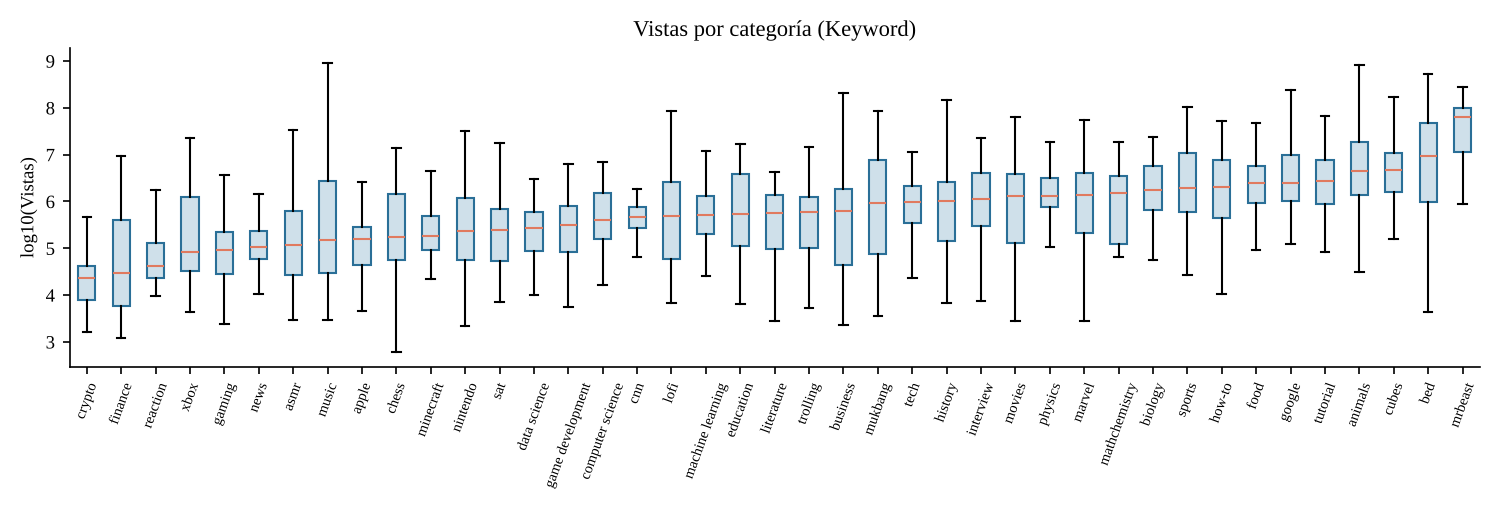

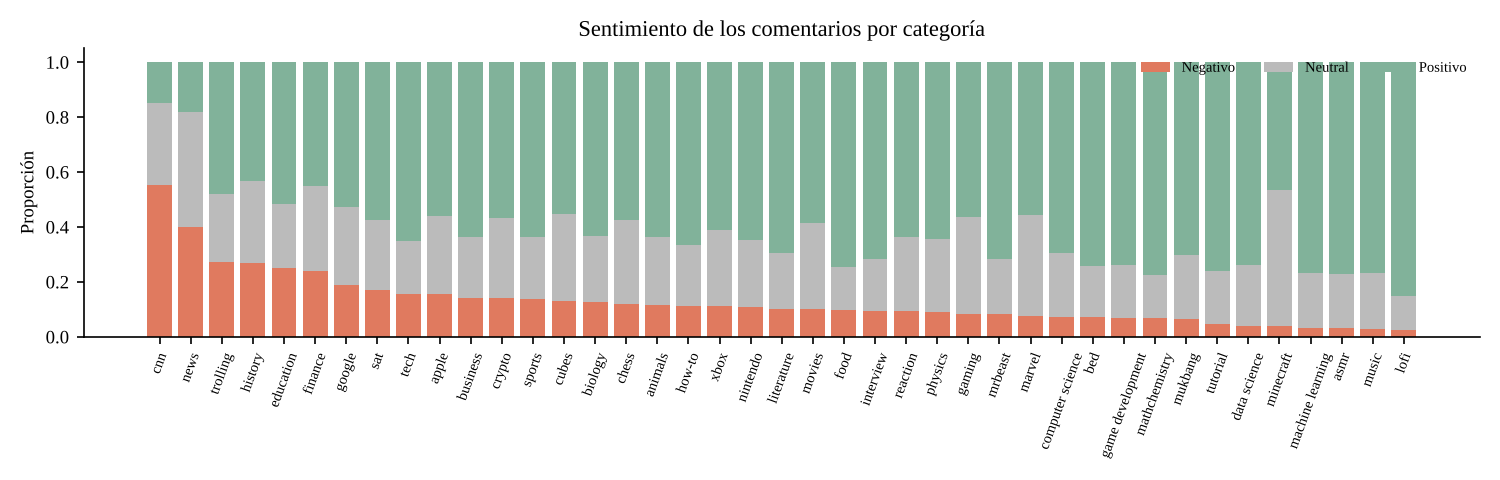

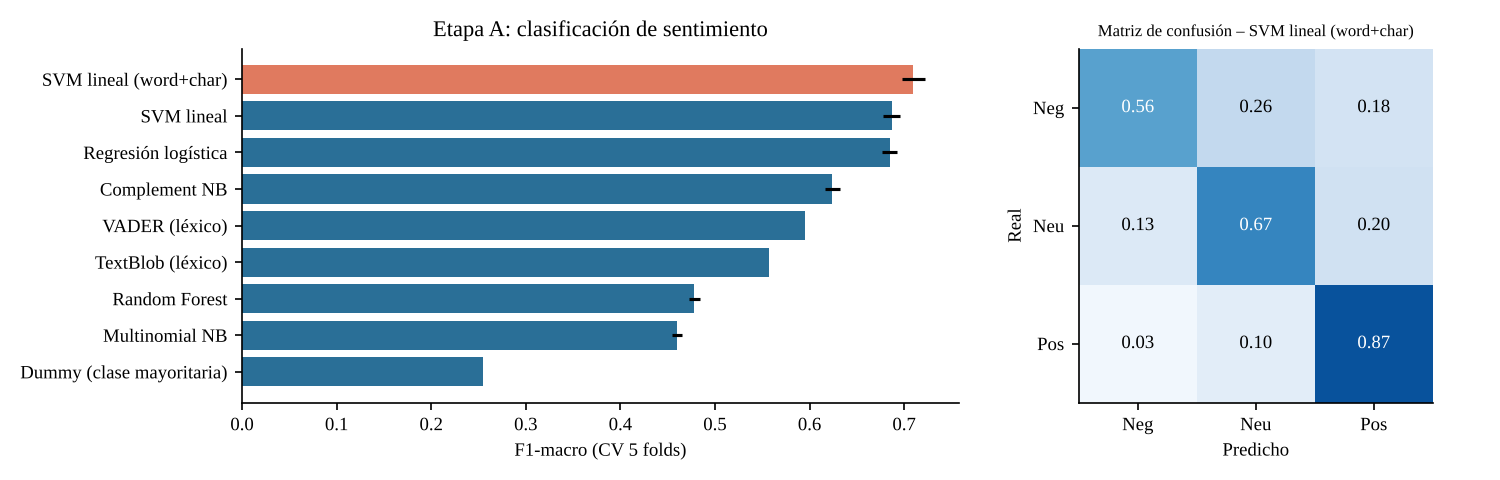

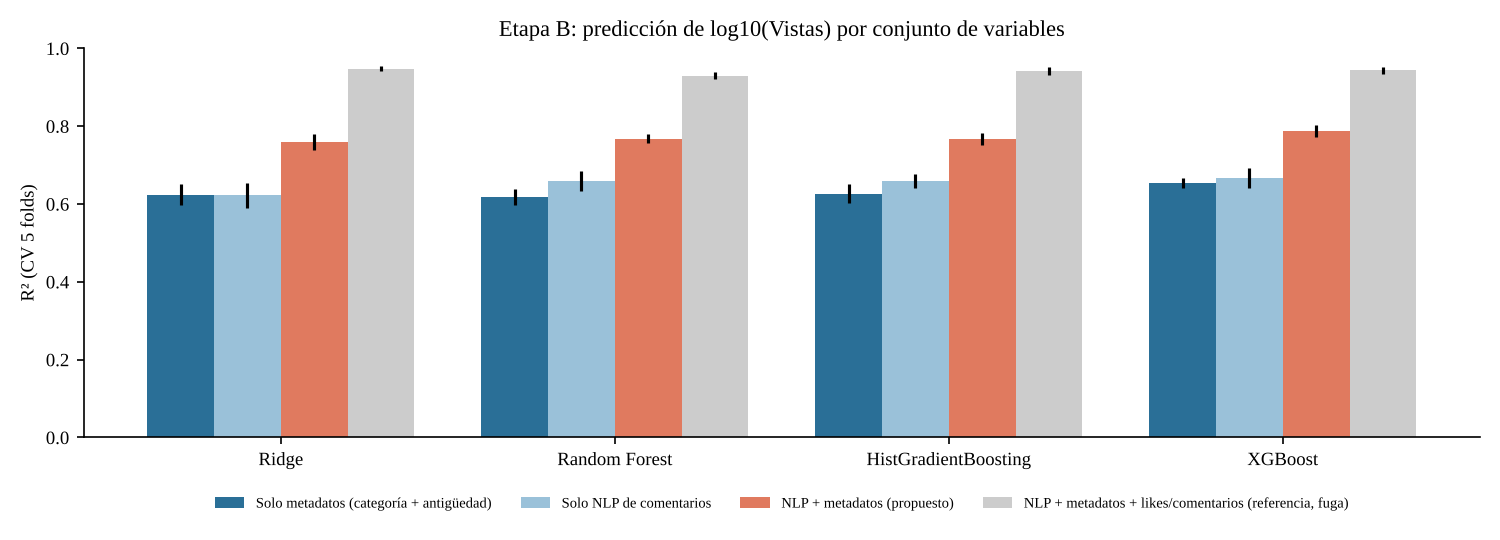

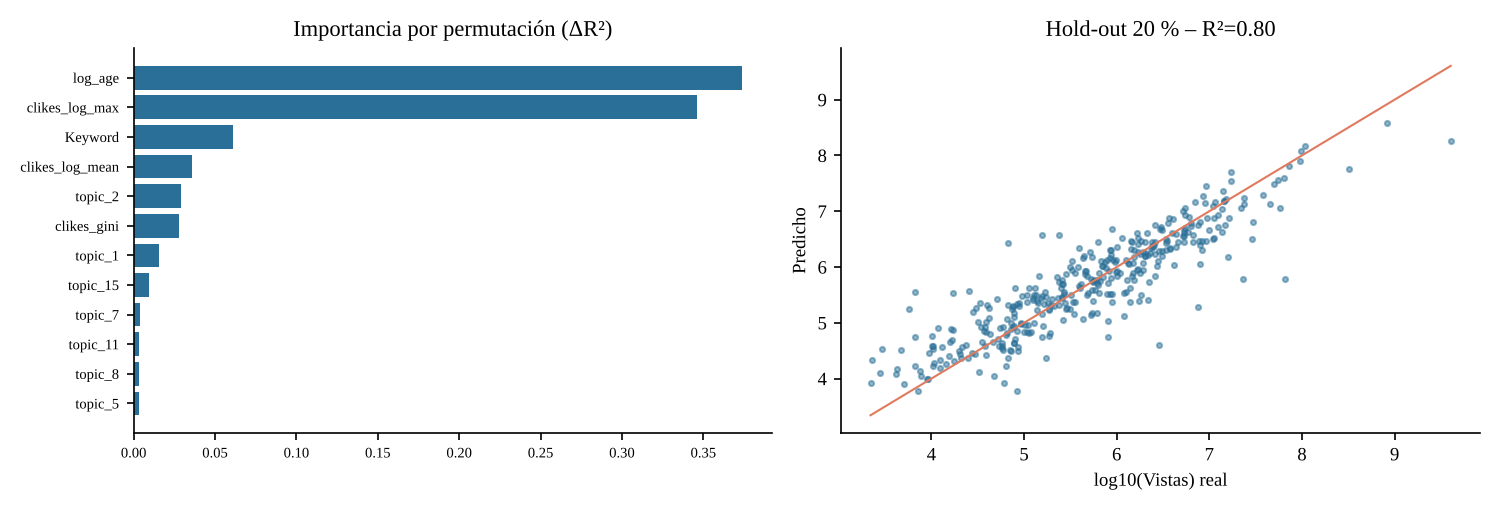

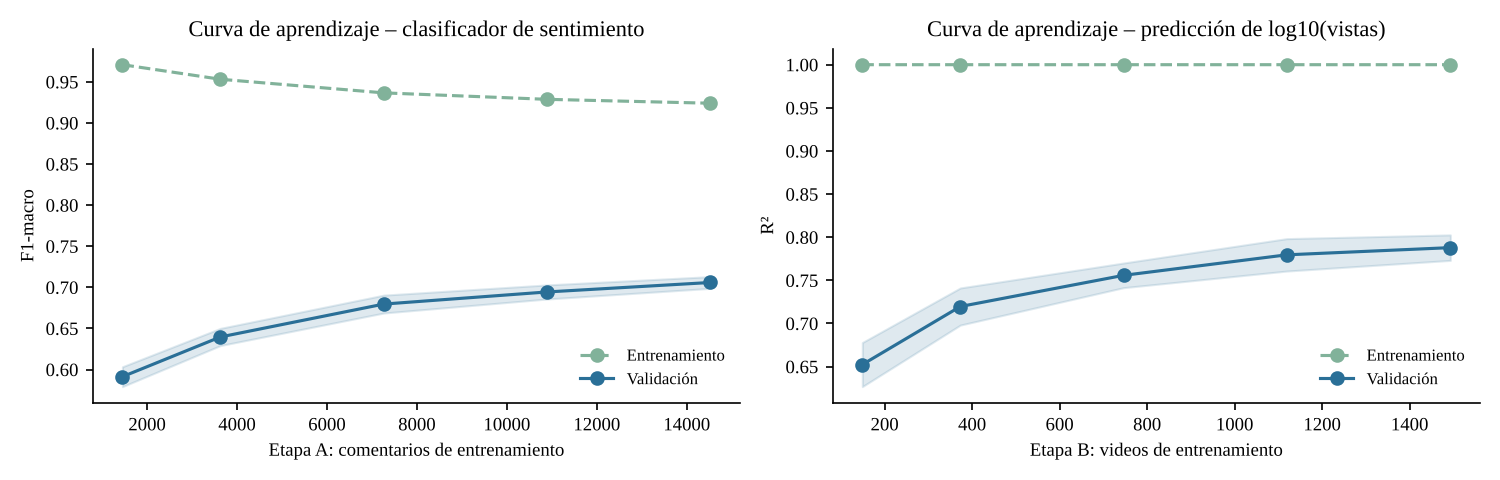

In [11]:
from IPython.display import Image, display
for f in sorted(OUT.glob('f*.png')): display(Image(filename=str(f)))